# Part 2 from Window Hyperparameter tuning

* I have found that the best window hyperparameter tuning would be an expanding window with a 0.03 recency weighting
* including `time_step` has resulted in better overall pr_auc results
* the poor performance observed in `time_step` 23 and 33 are the result of extreme class imbalance observed in both periods
----------

Here I will be focusing on soft_labelling features obtained from retrospective_labelling
* soft_label_weight values: `0.00 (baseline, no soft labelling), 0.05, 0.10, 0.15, 0.30, 0.50, 0.70, 0.90 `
* Confidence cut off: `0.6, 0.7, 0.8, 0.9, 0.95`

--------
#### Results:
* compared with having no soft labelling, all combinations of soft labelling usage had higher mean, median, worst pr_auc score, and lower standard deviation
* in general, lower confidence cutoffs (0.60, 0.70) performed better than higher confidence cutoffs. Out of the top 10 tuning combinations, 9 of them had a confidence cut off of 0.60 or 0.70
* Best parameter: `weighting method`: `constant`, `soft label weight`: `0.5`, `confidence cut off`: `0.7`
* It performed well, having the best mean roc-auc, having the best recent performance (from time_step 30-35)
* Although the linear method is another good contender (having the best median roc-auc), it had a notably higher standard deviation, indicating less stability
* Thus, I chose the Constant weighting method

In [1]:
# Candidate pools for the soft-label experiment.
# 0.20 is included as a useful midpoint between 0.15 and 0.30.

# original params (TOOK 10 HOURS TO TUNE): 0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 0.70, 0.90
soft_label_weights = [0.05, 0.15, 0.20, 0.30, 0.50, 0.70, 0.90]
confidence_cutoffs = [0.5, 0.60, 0.70, 0.80, 0.90, 0.95]
weighting_methods = ["constant", "linear", "squared"]

print("Soft-label weights:", soft_label_weights)
print("Confidence cutoffs:", confidence_cutoffs)
print("Weighting methods:", weighting_methods)
print("Non-zero tuning combinations:", (len(soft_label_weights) - 1) * len(confidence_cutoffs))

Soft-label weights: [0.05, 0.15, 0.2, 0.3, 0.5, 0.7, 0.9]
Confidence cutoffs: [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
Weighting methods: ['constant', 'linear', 'squared']
Non-zero tuning combinations: 36


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight
from lightgbm import LGBMClassifier


In [3]:
### Load data

train_raw = pd.read_csv("train.csv", header = 0) # original, no soft label
train_soft_label_raw = pd.read_csv("train_soft_label.csv", header = 0)
test_raw = pd.read_csv("test.csv", header = 0)
edges_raw = pd.read_csv("txs_edgelist.csv", header = 0)

In [4]:
labelled_train = train_raw[train_raw["label"].notna()].copy()
labelled_train["label"] = labelled_train["label"].astype(int)

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Edges shape:", edges_raw.shape)
print("Labelled rows:", len(labelled_train))
print(labelled_train["label"].value_counts())

Train shape: (141772, 168)
Test shape: (15329, 168)
Edges shape: (234355, 2)
Labelled rows: 31235
label
0    27591
1     3644
Name: count, dtype: int64


In [5]:
# Use the train/test time mapping to decide whether an edge endpoint is
# temporally available at a given cutoff.
node_times = pd.concat(
    [
        train_raw[["txId", "time_step"]],
        test_raw[["txId", "time_step"]],
    ],
    ignore_index=True,
).drop_duplicates("txId").set_index("txId")["time_step"]

edges = edges_raw[["txId1", "txId2"]].copy()
edges["time_1"] = edges["txId1"].map(node_times)
edges["time_2"] = edges["txId2"].map(node_times)

print("Edges with unknown endpoint time:", edges[["time_1", "time_2"]].isna().any(axis=1).sum())

Edges with unknown endpoint time: 58437


In [6]:
def temporal_node_features(cutoff_step):
    """Compute structural node features using edges available by cutoff_step."""
    usable_edges = edges[
        edges["time_1"].notna()
        & edges["time_2"].notna()
        & (edges["time_1"] <= cutoff_step)
        & (edges["time_2"] <= cutoff_step)
    ]

    in_degree = usable_edges.groupby("txId2").size().rename("in_degree")
    out_degree = usable_edges.groupby("txId1").size().rename("out_degree")

    features = pd.concat([in_degree, out_degree], axis=1).fillna(0)
    features["total_degree"] = (
        features["in_degree"] + features["out_degree"]
    )
    features["degree_ratio"] = (
        features["out_degree"]
        / features["in_degree"].replace(0, np.nan)
    )
    features["degree_ratio"] = (
        features["degree_ratio"]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    return features.reset_index().rename(columns={"index": "txId"})


graph_feature_cols = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_ratio",
]

In [7]:
def add_temporal_graph_features(frame, cutoff_step):
    graph_features = temporal_node_features(cutoff_step)
    result = frame.merge(graph_features, on="txId", how="left")
    result[graph_feature_cols] = result[graph_feature_cols].fillna(0)
    return result

In [8]:
def create_lightgbm():
    return LGBMClassifier(
        objective="binary",
        random_state=100,
        n_jobs=-1,
        verbosity=-1,
    )

def calculate_recency_weights(
    time_steps,
    reference_time_step,
    decay_rate,
):
    """
    Exponential recency weighting.

    More recent observations receive larger weights.
    """

    age = reference_time_step - time_steps

    weights = np.exp(
        -decay_rate * age
    )

    return weights

In [ ]:
feature_cols = [
    c for c in train_raw.columns # only look at feat_xxx, no node_info here
    if c not in ["txId", "label", "time_step"] #do not include time_step, has no improvement n slightly reduced roc
]

print("Original feature count:", len(feature_cols))

Original feature count: 165


Building training data for soft-labelling

In [10]:
soft_label_col = "p_illicit"

def calculate_confidence_weight(probabilities, soft_weight, weighting_method):
    """Return a source weight based on distance from an uncertain 0.5 prediction."""
    confidence = np.maximum(probabilities, 1.0 - probabilities)

    #convert into 0-1 scale:
    confidence_strength = (confidence - 0.5) / 0.5

    if weighting_method == "constant":
        multiplier = np.ones(len(probabilities))
    elif weighting_method == "linear":
        multiplier = confidence_strength
    elif weighting_method == "squared":
        multiplier = confidence_strength ** 2
    else:
        raise ValueError("weighting_method must be 'constant', 'linear', or 'squared'")

    return soft_weight * multiplier

def build_augmented_train(
    soft_weight,
    confidence_cutoff,
    weighting_method="constant",
):
    """Create confirmed plus high-confidence pseudo-labelled data."""

    confirmed = train_raw[train_raw["label"].notna()].copy()
    confirmed["training_label"] = confirmed["label"].astype(int)
    confirmed["label_source_weight"] = 1.0

    selected_columns = [
        "txId", "time_step", "training_label", "label_source_weight",
    ] + feature_cols
    selected_columns = list(dict.fromkeys(selected_columns))
    confirmed_keep = confirmed[selected_columns].copy()

    if soft_weight == 0.0:
        return confirmed_keep

    pseudo = train_soft_label_raw[
        train_soft_label_raw["label"].isna()
        & train_soft_label_raw[soft_label_col].notna()
    ].copy()
    pseudo = pseudo[
        (pseudo[soft_label_col] <= 1.0 - confidence_cutoff)
        | (pseudo[soft_label_col] >= confidence_cutoff)
    ].copy()

    pseudo["training_label"] = (pseudo[soft_label_col] >= 0.5).astype(int)
    pseudo["label_source_weight"] = calculate_confidence_weight(
        pseudo[soft_label_col].to_numpy(),
        soft_weight=soft_weight,
        weighting_method=weighting_method,
    )
    pseudo_keep = pseudo[selected_columns].copy()

    augmented = pd.concat([confirmed_keep, pseudo_keep], ignore_index=True)
    return augmented.loc[:, ~augmented.columns.duplicated()]


In [11]:
# Sanity-check one setting.
example_augmented_constant = build_augmented_train(
    soft_weight=0.20,
    confidence_cutoff=0.90,
    weighting_method="constant"
)

print("Example augmented rows:", len(example_augmented_constant))
print("Confirmed rows:", len(labelled_train))
print(
    "Additional pseudo-labelled rows:",
    len(example_augmented_constant) - len(labelled_train),
)

Example augmented rows: 126783
Confirmed rows: 31235
Additional pseudo-labelled rows: 95548


In [12]:
def evaluate_temporal_label_configuration(
    train_data,
    validation_data,
    feature_cols,
    strategy,
    window_size,
    recency_decay=0.0,
    min_validation_step=21,
    use_time_step=False,
    use_graph_features=True,
    train_label_col="training_label",
    validation_label_col="label",
    source_weight_col="label_source_weight",
    verbose=False,
):
    """Evaluate one temporal configuration using confirmed validation labels."""
    train_data = train_data.copy()
    validation_data = validation_data.copy()

    available_steps = sorted(
        validation_data["time_step"].dropna().unique()
    )
    fold_results = []

    for validation_step in available_steps:
        if validation_step < min_validation_step:
            continue

        train_end_step = validation_step - 1

        if strategy == "expanding":
            train_start_step = available_steps[0]
            historical_steps = [
                step for step in available_steps
                if step <= train_end_step
            ]
            if len(historical_steps) < window_size:
                continue

        elif strategy == "rolling":
            train_start_step = (
                train_end_step - window_size + 1
            )
        else:
            raise ValueError(
                "strategy must be 'expanding' or 'rolling'"
            )

        train_fold = train_data[
            (train_data["time_step"] >= train_start_step) &
            (train_data["time_step"] <= train_end_step) &
            train_data[train_label_col].notna()
        ].copy()

        validation_fold = validation_data[
            (validation_data["time_step"] == validation_step) &
            validation_data[validation_label_col].notna()
        ].copy()

        if train_fold.empty or validation_fold.empty:
            continue

        y_train = train_fold[train_label_col].astype(int)
        y_validation = validation_fold[validation_label_col].astype(int)

        if y_train.nunique() < 2 or y_validation.nunique() < 2:
            continue

        if use_graph_features:
            train_fold = add_temporal_graph_features(
                train_fold,
                cutoff_step=train_end_step,
            )
            validation_fold = add_temporal_graph_features(
                validation_fold,
                cutoff_step=validation_step,
            )

        fold_feature_cols = list(feature_cols)
        if use_graph_features:
            fold_feature_cols += graph_feature_cols
        if use_time_step:
            fold_feature_cols += ["time_step"]

        X_train = train_fold[fold_feature_cols]
        X_validation = validation_fold[fold_feature_cols]

        class_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train,
        )

        recency_weights = calculate_recency_weights(
            train_fold["time_step"].to_numpy(),
            reference_time_step=train_end_step,
            decay_rate=recency_decay,
        )

        if source_weight_col in train_fold.columns:
            source_weights = train_fold[
                source_weight_col
            ].to_numpy()
        else:
            source_weights = np.ones(len(train_fold))

        sample_weights = (
            class_weights
            * recency_weights
            * source_weights
        )
        sample_weights = (
            sample_weights / sample_weights.mean()
        )

        model = create_lightgbm()
        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights,
        )

        validation_probabilities = model.predict_proba(
            X_validation
        )[:, 1]

        if verbose:
            print(
                f"Train: {train_start_step}:{train_end_step} | "
                f"Validate: {validation_step}"
            )

        fold_results.append({
            "strategy": strategy,
            "window_size": window_size,
            "recency_decay": recency_decay,
            "validation_step": validation_step,
            "train_start_step": train_start_step,
            "train_end_step": train_end_step,
            "n_train": len(train_fold),
            "n_validation": len(validation_fold),
            "positive_train": int(y_train.sum()),
            "positive_validation": int(y_validation.sum()),
            "pr_auc": average_precision_score(
                y_validation,
                validation_probabilities,
            ),
            "roc_auc": roc_auc_score(
                y_validation,
                validation_probabilities,
            ),
        })

    return pd.DataFrame(fold_results)


Create label baseline

In [13]:
confirmed_results = evaluate_temporal_label_configuration(
    train_data=labelled_train,
    validation_data=labelled_train,
    feature_cols=feature_cols,
    strategy="expanding",
    window_size=20, # best window size from window_hyperparam
    recency_decay=0.03, # best recency decay from window_hyperparam
    min_validation_step=21,
    use_time_step=False,
    use_graph_features=True,
    train_label_col="label",
    validation_label_col="label",
)

confirmed_results = confirmed_results.assign(
    soft_label_weight=0.00,
    confidence_cutoff=np.nan,
    n_pseudo=0,
)

display(confirmed_results.head())

,strategy,window_size,recency_decay,validation_step,train_start_step,train_end_step,n_train,n_validation,positive_train,positive_validation,pr_auc,roc_auc,soft_label_weight,confidence_cutoff,n_pseudo
0,expanding,20,0.03,21,1,20,18889,641,1771,100,0.985498,0.995749,0.0,NaN,0
1,expanding,20,0.03,22,1,21,19530,1763,1871,158,0.993533,0.999231,0.0,NaN,0
2,expanding,20,0.03,23,1,22,21293,1187,2029,53,0.798304,0.963346,0.0,NaN,0
3,expanding,20,0.03,24,1,23,22480,1126,2082,137,0.972598,0.994059,0.0,NaN,0
4,expanding,20,0.03,25,1,24,23606,594,2219,118,0.999130,0.999786,0.0,NaN,0


Run soft label grid:

In [14]:
tuning_results = [confirmed_results]

for weighting_method in weighting_methods:
    for soft_weight in soft_label_weights:
        if soft_weight == 0.0:
            continue

        for confidence_cutoff in confidence_cutoffs:
            augmented_train = build_augmented_train(
                soft_weight=soft_weight,
                confidence_cutoff=confidence_cutoff,
                weighting_method=weighting_method,
            )

            pseudo_count = len(augmented_train) - len(labelled_train)
            print(
                f"method={weighting_method}, "
                f"weight={soft_weight:.2f}, "
                f"cutoff={confidence_cutoff:.2f}, "
                f"pseudo_rows={pseudo_count:,}"
            )

            result = evaluate_temporal_label_configuration(
                train_data=augmented_train,
                validation_data=labelled_train,
                feature_cols=feature_cols,
                strategy="expanding",
                window_size=20,
                recency_decay=0.03,
                min_validation_step=21,
                use_time_step=False,
                use_graph_features=True,
                train_label_col="training_label",
                validation_label_col="label",
                source_weight_col="label_source_weight",
            )

            result = result.assign(
                weighting_method=weighting_method,
                soft_label_weight=soft_weight,
                confidence_cutoff=confidence_cutoff,
                n_pseudo=pseudo_count,
            )
            tuning_results.append(result)

tuning_fold_results = pd.concat(tuning_results, ignore_index=True)
print("Total fold results:", len(tuning_fold_results))


method=constant, weight=0.05, cutoff=0.50, pseudo_rows=110,537
method=constant, weight=0.05, cutoff=0.60, pseudo_rows=108,294
method=constant, weight=0.05, cutoff=0.70, pseudo_rows=105,509
method=constant, weight=0.05, cutoff=0.80, pseudo_rows=101,784
method=constant, weight=0.05, cutoff=0.90, pseudo_rows=95,548
method=constant, weight=0.05, cutoff=0.95, pseudo_rows=89,085
method=constant, weight=0.15, cutoff=0.50, pseudo_rows=110,537
method=constant, weight=0.15, cutoff=0.60, pseudo_rows=108,294
method=constant, weight=0.15, cutoff=0.70, pseudo_rows=105,509
method=constant, weight=0.15, cutoff=0.80, pseudo_rows=101,784
method=constant, weight=0.15, cutoff=0.90, pseudo_rows=95,548
method=constant, weight=0.15, cutoff=0.95, pseudo_rows=89,085
method=constant, weight=0.20, cutoff=0.50, pseudo_rows=110,537
method=constant, weight=0.20, cutoff=0.60, pseudo_rows=108,294
method=constant, weight=0.20, cutoff=0.70, pseudo_rows=105,509
method=constant, weight=0.20, cutoff=0.80, pseudo_rows=101,

In [15]:
tuning_summary = (
    tuning_fold_results
    .groupby(
        ["weighting_method", "soft_label_weight", "confidence_cutoff"],
        dropna=False,
    )
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        median_roc_auc=("roc_auc", "median"),
        std_roc_auc=("roc_auc", "std"),
        worst_roc_auc=("roc_auc", "min"),
        latest_5_roc_auc=("roc_auc", lambda x: x.tail(5).mean()),
        mean_pr_auc=("pr_auc", "mean"),
        n_folds=("validation_step", "count"),
        n_pseudo=("n_pseudo", "first"),
    )
    .reset_index()
    .sort_values(
        ["mean_roc_auc", "latest_5_roc_auc"],
        ascending=False,
    )
)

display(tuning_summary)

print("Top candidate setting for each weighting method:")

top_candidate_by_method = (
    tuning_summary[
        tuning_summary["weighting_method"].isin(
            ["constant", "linear", "squared"]
        )
    ]
    .sort_values(
        [
            "weighting_method",
            "mean_roc_auc",
            "latest_5_roc_auc",
        ],
        ascending=[True, False, False],
    )
    .groupby(
        "weighting_method",
        as_index=False,
    )
    .head(1)
    .reset_index(drop=True)
)

display(top_candidate_by_method)

,weighting_method,soft_label_weight,confidence_cutoff,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds,n_pseudo
2,constant,0.05,0.70,0.997028,0.998723,0.004582,0.982813,0.998416,0.981410,15,105509
75,linear,0.70,0.80,0.996945,0.998863,0.005090,0.980001,0.998365,0.981930,15,101784
84,squared,0.05,0.50,0.996945,0.998374,0.004455,0.983561,0.998066,0.980903,15,110537
92,squared,0.15,0.70,0.996930,0.998553,0.004738,0.981798,0.998127,0.980798,15,105509
43,linear,0.05,0.60,0.996916,0.998399,0.004294,0.984127,0.998311,0.981648,15,108294
...,...,...,...,...,...,...,...,...,...,...,...
77,linear,0.70,0.95,0.995689,0.998583,0.007636,0.969918,0.998029,0.975677,15,89085
113,squared,0.50,0.95,0.995522,0.997748,0.007865,0.969236,0.998015,0.975481,15,89085
71,linear,0.50,0.95,0.995512,0.998162,0.006890,0.973894,0.997080,0.974135,15,89085
23,constant,0.30,0.95,0.995506,0.998362,0.008870,0.964826,0.997752,0.975658,15,89085


Top candidate setting for each weighting method:


,weighting_method,soft_label_weight,confidence_cutoff,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds,n_pseudo
0,constant,0.05,0.7,0.997028,0.998723,0.004582,0.982813,0.998416,0.981410,15,105509
1,linear,0.70,0.8,0.996945,0.998863,0.005090,0.980001,0.998365,0.981930,15,101784
2,squared,0.05,0.5,0.996945,0.998374,0.004455,0.983561,0.998066,0.980903,15,110537


In [16]:
print("Methods:")
print(tuning_fold_results["weighting_method"].unique())

print("Soft weights:")
print(sorted(tuning_fold_results["soft_label_weight"].dropna().unique()))

print("Cutoffs:")
print(sorted(tuning_fold_results["confidence_cutoff"].dropna().unique()))

Methods:
[nan 'constant' 'linear' 'squared']
Soft weights:
[np.float64(0.0), np.float64(0.05), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.5), np.float64(0.7), np.float64(0.9)]
Cutoffs:
[np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(0.95)]


Compare with confirmed-only baseline

In [17]:
baseline_mean = tuning_summary.loc[
    tuning_summary["soft_label_weight"] == 0.0,
    "mean_roc_auc",
].iloc[0]

tuning_summary["mean_roc_auc_difference_vs_baseline"] = (
    tuning_summary["mean_roc_auc"] - baseline_mean
)

display(
    tuning_summary.sort_values(
        "mean_roc_auc_difference_vs_baseline",
        ascending=False,
    )
)

,weighting_method,soft_label_weight,confidence_cutoff,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds,n_pseudo,mean_roc_auc_difference_vs_baseline
2,constant,0.05,0.70,0.997028,0.998723,0.004582,0.982813,0.998416,0.981410,15,105509,0.002095
75,linear,0.70,0.80,0.996945,0.998863,0.005090,0.980001,0.998365,0.981930,15,101784,0.002012
84,squared,0.05,0.50,0.996945,0.998374,0.004455,0.983561,0.998066,0.980903,15,110537,0.002012
92,squared,0.15,0.70,0.996930,0.998553,0.004738,0.981798,0.998127,0.980798,15,105509,0.001997
43,linear,0.05,0.60,0.996916,0.998399,0.004294,0.984127,0.998311,0.981648,15,108294,0.001983
...,...,...,...,...,...,...,...,...,...,...,...,...
77,linear,0.70,0.95,0.995689,0.998583,0.007636,0.969918,0.998029,0.975677,15,89085,0.000756
113,squared,0.50,0.95,0.995522,0.997748,0.007865,0.969236,0.998015,0.975481,15,89085,0.000588
71,linear,0.50,0.95,0.995512,0.998162,0.006890,0.973894,0.997080,0.974135,15,89085,0.000579
23,constant,0.30,0.95,0.995506,0.998362,0.008870,0.964826,0.997752,0.975658,15,89085,0.000573


Plot ROC-AUC by weight and cutoff

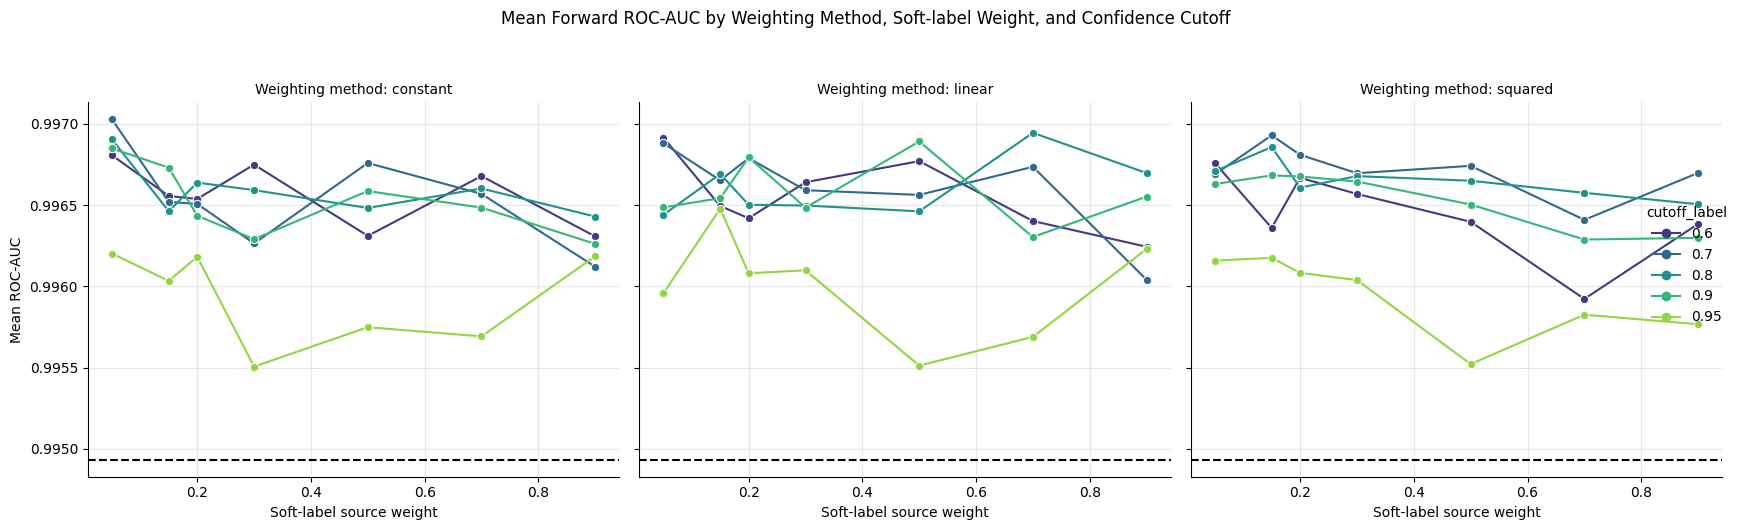

In [23]:
plot_data = tuning_summary.copy()

plot_data = plot_data[
    plot_data["weighting_method"].isin(
        ["constant", "linear", "squared"]
    )
].copy()

cutoff_order = ["0.6", "0.7", "0.8", "0.9", "0.95"]

plot_data["cutoff_label"] = pd.Categorical(
    plot_data["confidence_cutoff"].astype(str),
    categories=cutoff_order,
    ordered=True,
)

plot_data = plot_data.sort_values(
    ["weighting_method", "cutoff_label", "soft_label_weight"]
)

g = sns.relplot(
    data=plot_data,
    x="soft_label_weight",
    y="mean_roc_auc",
    hue="cutoff_label",
    hue_order=cutoff_order,
    col="weighting_method",
    col_order=["constant", "linear", "squared"],
    kind="line",
    marker="o",
    palette="viridis",
    height=5,
    aspect=1.1,
)

for ax in g.axes.flat:
    ax.axhline(
        baseline_mean,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Confirmed-only baseline",
    )
    ax.grid(alpha=0.3)
    ax.set_xlabel("Soft-label source weight")
    ax.set_ylabel("Mean ROC-AUC")

g.set_titles("Weighting method: {col_name}")

g.figure.suptitle(
    "Mean Forward ROC-AUC by Weighting Method, "
    "Soft-label Weight, and Confidence Cutoff",
    y=1.05,
)

plt.tight_layout()
plt.show()

Plot ROC-AUC across validation periods

Best parameter setting for each weighting method:


,weighting_method,soft_label_weight,confidence_cutoff,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds,n_pseudo,mean_roc_auc_difference_vs_baseline
0,constant,0.05,0.7,0.997028,0.998723,0.004582,0.982813,0.998416,0.981410,15,105509,0.002095
1,linear,0.70,0.8,0.996945,0.998863,0.005090,0.980001,0.998365,0.981930,15,101784,0.002012
2,squared,0.05,0.5,0.996945,0.998374,0.004455,0.983561,0.998066,0.980903,15,110537,0.002012


,method_label,validation_step,pr_auc,roc_auc
0,Constant,21,0.990849,0.997523
1,Constant,22,0.995779,0.999543
2,Constant,23,0.873890,0.982813
3,Constant,24,0.986804,0.997587
4,Constant,25,0.999259,0.999822


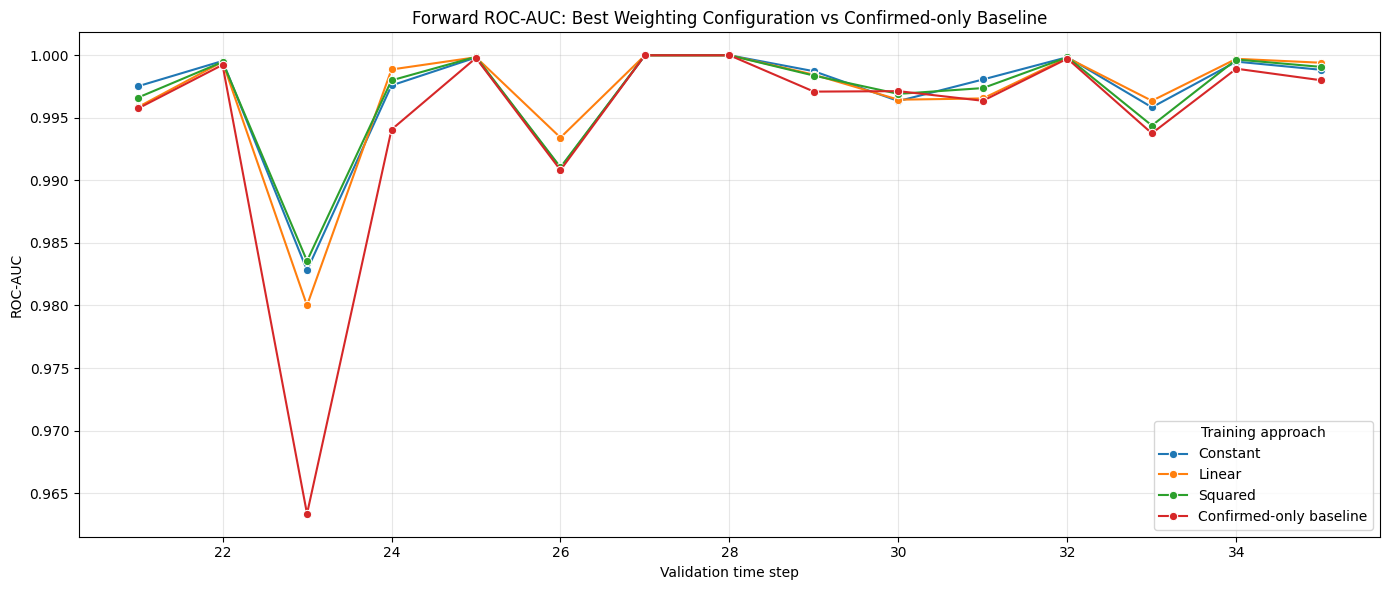

In [19]:
# Select the best parameter combination for each weighting method.
top_setting_by_method = (
    tuning_summary[
        tuning_summary["weighting_method"].isin(
            ["constant", "linear", "squared"]
        )
    ]
    .sort_values(
        ["weighting_method", "mean_roc_auc", "latest_5_roc_auc"],
        ascending=[True, False, False],
    )
    .groupby("weighting_method", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

print("Best parameter setting for each weighting method:")
display(top_setting_by_method)


# Retrieve fold-level results for each method's best configuration.
best_results_by_method = []

for _, setting in top_setting_by_method.iterrows():

    method_results = tuning_fold_results[
        (tuning_fold_results["weighting_method"] == setting["weighting_method"])
        & (
            tuning_fold_results["soft_label_weight"]
            == setting["soft_label_weight"]
        )
        & (
            tuning_fold_results["confidence_cutoff"]
            == setting["confidence_cutoff"]
        )
    ].copy()

    method_results["method_label"] = (
        setting["weighting_method"].capitalize()
    )

    best_results_by_method.append(method_results)


# Add the confirmed-only baseline.
baseline_results = confirmed_results.copy()
baseline_results["method_label"] = "Confirmed-only baseline"

best_results_by_method.append(baseline_results)


# Combine all results.
best_results_by_method = pd.concat(
    best_results_by_method,
    ignore_index=True,
)

display(
    best_results_by_method[
        [
            "method_label",
            "validation_step",
            "pr_auc",
            "roc_auc",
        ]
    ].head()
)


# Plot fold-level PR-AUC.
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=best_results_by_method,
    x="validation_step",
    y="roc_auc",
    hue="method_label",
    marker="o",
)

plt.title(
    "Forward ROC-AUC: Best Weighting Configuration vs Confirmed-only Baseline"
)
plt.xlabel("Validation time step")
plt.ylabel("ROC-AUC")
plt.grid(alpha=0.3)
plt.legend(title="Training approach")
plt.tight_layout()
plt.show()

In [20]:
method_comparison = (
    best_results_by_method
    .groupby("method_label")
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        median_roc_auc=("roc_auc", "median"),
        std_roc_auc=("roc_auc", "std"),
        worst_roc_auc=("roc_auc", "min"),
        latest_5_roc_auc=("roc_auc", lambda x: x.tail(5).mean()),
        n_folds=("roc_auc", "count"),
    )
    .sort_values("mean_roc_auc", ascending=False)
)

display(method_comparison)

,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,n_folds
method_label,,,,,,
Constant,0.997028,0.998723,0.004582,0.982813,0.998416,15
Linear,0.996945,0.998863,0.005090,0.980001,0.998365,15
Squared,0.996945,0.998374,0.004455,0.983561,0.998066,15
Confirmed-only baseline,0.994933,0.997131,0.009145,0.963346,0.997356,15
